In [16]:
import torch
import torch.nn as nn

import numpy as np
from matplotlib import pyplot

import math
import seaborn as sns

In [17]:
class NN(nn.Module):
    def __init__(self):
        super(NN, self).__init__()
        self.net = torch.nn.Sequential(
            nn.Linear(2,20),
            nn.Tanh(),
            nn.Linear(20,30),
            nn.Tanh(),
            nn.Linear(30,30),
            nn.Tanh(),
            nn.Linear(30,20),
            nn.Tanh(),
            nn.Linear(20,20),
            nn.Tanh(),
            nn.Linear(20,1)


        )


    def forward(self, x):
        out = self.net(x)
        return out


In [18]:
class Net:
    def __init__(self):
        device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
        self.model = NN().to(device)



        self.h = 0.1
        self.k = 0.1

        x =torch.arange(-1, 1+self.h, self.h) # 空间网格
        t =  torch.arange(0, 1+self.k, self.k)

        self.X = torch.stack(torch.meshgrid(x, t)).reshape(2,-1).T


        # train data
        bc1 = torch.stack(torch.meshgrid(x[0], t)).reshape(2,-1).T
        bc2 = torch.stack(torch.meshgrid(x[-1], t)).reshape(2,-1).T
        ic = torch.stack(torch.meshgrid(x,t[0])).reshape(2,-1).T
        self.X_train = torch.cat([bc1, bc2, ic])


        y_bc1 = torch.zeros(len(bc1))
        y_bc2 = torch.zeros(len(bc2))
        y_ic = -torch.sin(math.pi*ic[:,0])
        self.y_train = torch.cat([y_bc1, y_bc2, y_ic])
        self.y_train = self.y_train.unsqueeze(1)

        self.X = self.X.to(device)
        self.y_train = self.y_train.to(device)
        self.X_train = self.X_train.to(device)
        self.X.requires_grad = True


        # 优化器选择
        self.adam = torch.optim.Adam(self.model.parameters())
        self.optimizer = torch.optim.LBFGS(
            self.model.parameters(),
            lr = 1.0,
            max_iter = 50000, 
            max_eval = 50000,
            history_size = 50, 
            tolerance_grad= 1e-7,
            tolerance_change=  1.0*np.finfo(float).eps,
            line_search_fn="strong_wolfe"

        )

        self.criterion = torch.nn.MSELoss()
        self.iter = 1


    def loss_func(self):
        self.adam.zero_grad()
        self.optimizer.zero_grad()


        y_pred  = self.model(self.X_train)
        loss_data = self.criterion(y_pred, self.y_train)


        u = self.model(self.X)

        du_dX = torch.autograd.grad(
            u,
            self.X,
            grad_outputs = torch.ones_like(u),
            create_graph=True,
            retain_graph=True

        )[0]

        du_dt = du_dX[:,1]
        du_dx = du_dX[:,0]

        du_dxx = torch.autograd.grad(
            du_dx, self.X,
            grad_outputs=torch.ones_like(du_dx),
            create_graph=True
        )[0][:, 0]

        loss_pde = self.criterion(du_dt + u.squeeze()*du_dx, (0.01/math.pi)*du_dxx)


        loss = loss_data + loss_pde
        loss.backward()


        if self.iter % 100 == 0:
            print(self.iter, loss.item())
        self.iter = self.iter + 1

        return loss
        
    def train(self):
        self.model.train()
        for i in range (1000):
            self.adam.step(self.loss_func)
        self.optimizer.step(self.loss_func)


    def eval_(self):
        self.model.eval()
        


                
            




In [19]:
# 训练
net = Net()
net.train()

100 0.1894197165966034
200 0.09083996713161469
300 0.06723862886428833
400 0.04203891381621361
500 0.024845613166689873
600 0.023650404065847397
700 0.01778930053114891
800 0.011789793148636818
900 0.012941977009177208
1000 0.009785998612642288
1100 0.0049083721823990345
1200 0.003159522544592619
1300 0.001848304527811706
1400 0.0011069444008171558
1500 0.0008742160862311721
1600 0.0006442086305469275
1700 0.00046802626457065344
1800 0.0003315389039926231
1900 0.0002481843112036586
2000 0.00019531816360540688
2100 0.00016852655971888453
2200 0.00014708554954268038
2300 0.00013748265337198973
2400 0.00012338566011749208
2500 0.0001096150153898634
2600 0.00010053332516690716
2700 9.298241639044136e-05
2800 8.658120350446552e-05
2900 8.035300561459735e-05
3000 7.172180630732328e-05
3100 6.4822866988834e-05
3200 6.0805210523540154e-05
3300 5.6039265473373234e-05
3400 7.670916966162622e-05
3500 5.054385110270232e-05
3600 4.7393088607350364e-05
3700 4.594371421262622e-05
3800 4.5014894567430

In [20]:
net.model.eval()

NN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=20, bias=True)
    (1): Tanh()
    (2): Linear(in_features=20, out_features=30, bias=True)
    (3): Tanh()
    (4): Linear(in_features=30, out_features=30, bias=True)
    (5): Tanh()
    (6): Linear(in_features=30, out_features=20, bias=True)
    (7): Tanh()
    (8): Linear(in_features=20, out_features=20, bias=True)
    (9): Tanh()
    (10): Linear(in_features=20, out_features=1, bias=True)
  )
)

In [21]:
h = 0.01

In [22]:
k = 0.01

In [23]:
x = torch.arange(-1, 1, h)
t = torch.arange(0, 1, k)

X = torch.stack(torch.meshgrid(x, t)).reshape(2, -1).T
X = X.to(net.X.device)
X

tensor([[-1.0000,  0.0000],
        [-1.0000,  0.0100],
        [-1.0000,  0.0200],
        ...,
        [ 0.9900,  0.9700],
        [ 0.9900,  0.9800],
        [ 0.9900,  0.9900]], device='cuda:0')

In [24]:
X.shape

torch.Size([20000, 2])

In [25]:
model = net.model
model.eval()
with torch.no_grad():
    y_pred = model(X)
    y_pred = y_pred.reshape(len(x), len(t)).cpu().numpy()

y_pred.shape

(200, 100)

In [26]:
y_pred

array([[ 9.35792923e-06, -7.50124454e-05, -1.48922205e-04, ...,
        -6.21974468e-05, -3.97264957e-05, -1.60038471e-05],
       [ 3.24938595e-02,  3.13962698e-02,  3.03658396e-02, ...,
         7.68332183e-03,  7.64584541e-03,  7.60996342e-03],
       [ 6.47037774e-02,  6.26157820e-02,  6.06507659e-02, ...,
         1.54327005e-02,  1.53344423e-02,  1.52392387e-02],
       ...,
       [-9.58815813e-02, -9.28584635e-02, -9.00315344e-02, ...,
        -2.31533945e-02, -2.29844749e-02, -2.28199363e-02],
       [-6.40431643e-02, -6.19972348e-02, -6.00946844e-02, ...,
        -1.54024959e-02, -1.52947009e-02, -1.51903331e-02],
       [-3.20005715e-02, -3.09540331e-02, -2.99952626e-02, ...,
        -7.65535235e-03, -7.60859251e-03, -7.56454468e-03]],
      shape=(200, 100), dtype=float32)

In [27]:
import matplotlib.pyplot as plt

sns.set_style("white")
plt.figure(figsize=(5,3), dpi = 3000)
sns.heatmap(y_pred,cmap='viridis')

<Axes: >

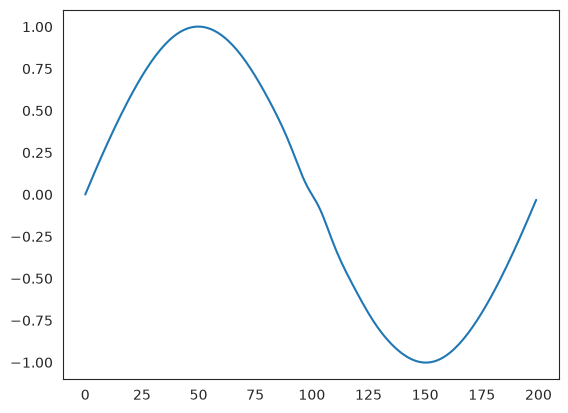

In [28]:
plt.plot(y_pred[:,0])

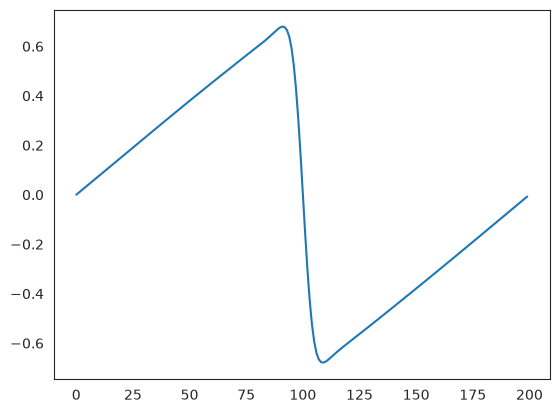

In [29]:
plt.plot(y_pred[:,-1])

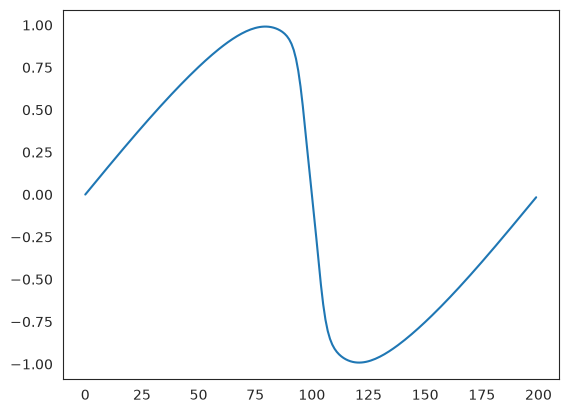

In [30]:
plt.plot(y_pred[:,30])